# Sistemas Inteligentes

## Exercício Computacional 2 - Classificação

Preencha todas as células adequadamente e responda todas as perguntas de forma completa e elaborada.

### Identificação do Aluno

#### Nome Completo

NICOLAS GARCIA DE SOUZA SANTOS

#### RA

11202520227


### Instruções

Treine e teste um classificador à sua escolha utilizando a base de dados **Olivetti Faces** (veja as referências).

Faça um caso com com *k-Fold* e um caso de forma direta, ou seja, utilizando o *train_test_split*.

Exiba a acurácia e a *Confusion Matrix*, então discuta sobre o desempenho do classificador para os dois casos.

Entre as células de códigos, insira células de tipo *Markdown* para fornecer explicações sobre os passos realizados; não insira apenas códigos "soltos" sem explicação.

Dica: desta vez, estamos lidando com uma quantidade relativamente grande de classes, então pode ser interessante exibir a *Confusion Matrix* utilizando escala de cinza para representar os valores de cada célula da matriz; para fazer isso, prefira utilizar a função **imshow** com o mapa de cores (argumento **cmap**) do tipo **'Greys'**.

**EXTRA**: tente fazer um caso com *Bootstrap* em vez de *k-Fold*, então comente sobre o método e os resultados.

# **IMPORTANDO A BASE E PREPARANDO OS DADOS**

In [3]:
#Importando a base de dados:

from sklearn.datasets import fetch_olivetti_faces

#Atribuindo a função a uma variável:

olivetti_faces = fetch_olivetti_faces()

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data


In [4]:
# Atribuindo as imagens do dataset a uma variável

faces_img = olivetti_faces.images

#Remodelando os dados do dataset para se adequarem ao formato a ser analisado:

faces = olivetti_faces.data
# Atribuindo o alvo do dataset a uma variável

faces_target = olivetti_faces.target

Formato de faces_img: (400, 64, 64)
Formato de faces (data): (400, 4096)
Formato de faces_target: (400,)


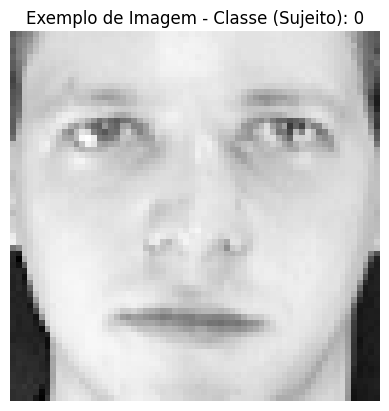

In [5]:
#Validando os formatos

import matplotlib.pyplot as plt
import numpy as np

print("Formato de faces_img:", faces_img.shape)
print("Formato de faces (data):", faces.shape)
print("Formato de faces_target:", faces_target.shape)

plt.imshow(faces_img[0], cmap="Greys_r")
plt.title(f"Exemplo de Imagem - Classe (Sujeito): {faces_target[0]}")
plt.axis("off")
plt.show()

# **DESENVOLVIMENTO COM TRAIN_TEST_SPLIT**

In [6]:
# Realizando a divisão dos grupos de treinamento e teste com train_test_split
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    faces, faces_target, test_size=0.25, random_state=99
)

print("Formato x_train:", x_train.shape)
print("Formato x_test:", x_test.shape)

Formato x_train: (300, 4096)
Formato x_test: (100, 4096)


In [7]:
#Treinando o classificador

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis()
lda = lda.fit(x_train, y_train)
y_pred_lda = lda.predict(x_test)

In [8]:
#Observando os resultados com acurácia

from sklearn.metrics import accuracy_score, confusion_matrix

acc_split = accuracy_score(y_test, y_pred_lda)
print(f"Acurácia (train_test_split): {acc_split:.4f}")

Acurácia (train_test_split): 0.9800


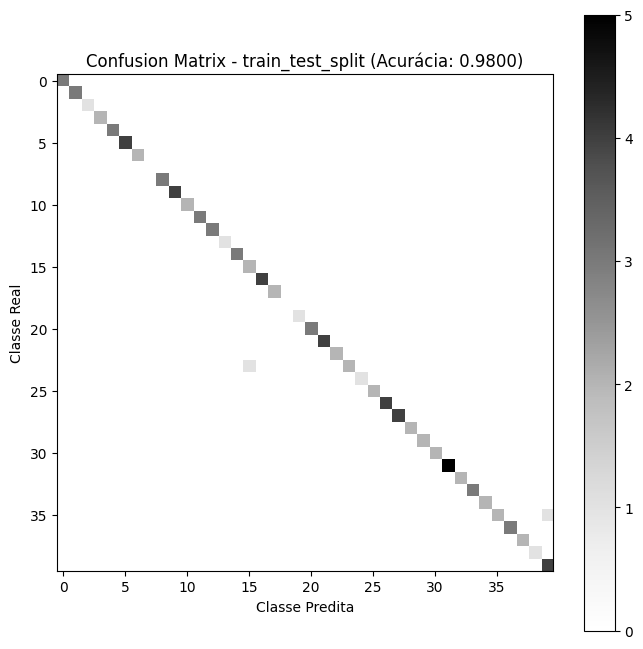

In [10]:
#Observando os resultados com matriz de confusão

cm_split = confusion_matrix(y_test, y_pred_lda, labels=range(40))

plt.figure(figsize=(8, 8))
plt.imshow(cm_split, cmap="Greys")
plt.title(f"Confusion Matrix - train_test_split (Acurácia: {acc_split:.4f})")
plt.xlabel("Classe Predita")
plt.ylabel("Classe Real")
plt.colorbar()
plt.show()

# **DESENVOLVIMENTO COM K-FOLD**

In [11]:
# Realizando a divisão dos grupos de treinamento e teste com k-fold e treinando o modelo
from sklearn.model_selection import KFold

X = faces
y = faces_target

kf = KFold(n_splits=5, shuffle=True, random_state=99)

acuracias_kf = []
cm_kfold = np.zeros((40, 40), dtype=int)

for i, (train_index, test_index) in enumerate(kf.split(X)):
    x_train, x_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    lda_kf = LinearDiscriminantAnalysis()
    lda_kf = lda_kf.fit(x_train, y_train)
    y_pred_kf = lda_kf.predict(x_test)

    acc_fold = accuracy_score(y_test, y_pred_kf)
    acuracias_kf.append(acc_fold)
    cm_kfold += confusion_matrix(y_test, y_pred_kf, labels=range(40))

    print(
        f"Fold {i}: treino={len(train_index)}, teste={len(test_index)} | Acurácia = {acc_fold:.4f}"
    )

Fold 0: treino=320, teste=80 | Acurácia = 0.9750
Fold 1: treino=320, teste=80 | Acurácia = 1.0000
Fold 2: treino=320, teste=80 | Acurácia = 0.9500
Fold 3: treino=320, teste=80 | Acurácia = 0.9750
Fold 4: treino=320, teste=80 | Acurácia = 0.9875


In [15]:
#Observando os resultados com acurácia

acc_media_kf = np.mean(acuracias_kf)
acc_std_kf = np.std(acuracias_kf)

print(f"Acurácia Média (k-Fold): {acc_media_kf:.4f}")
print(f"Desvio Padrão (k-Fold): {acc_std_kf:.4f}")

Acurácia Média (k-Fold): 0.9775
Desvio Padrão (k-Fold): 0.0166


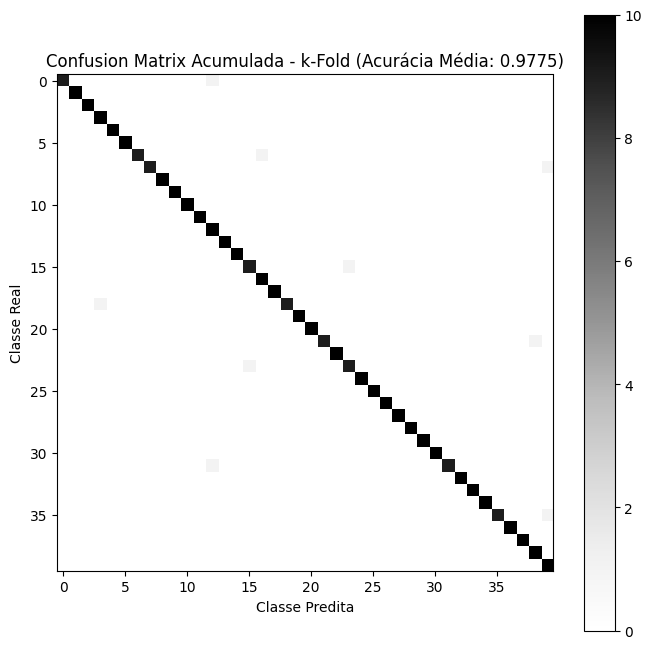

In [14]:
#Observando os resultados com matriz de confusão

plt.figure(figsize=(8, 8))
plt.imshow(cm_kfold, cmap="Greys")
plt.title(
    f"Confusion Matrix Acumulada - k-Fold (Acurácia Média: {acc_media_kf:.4f})"
)
plt.xlabel("Classe Predita")
plt.ylabel("Classe Real")
plt.colorbar()
plt.show()

# **DESENVOLVIMENTO COM BOOTSTRAP**

In [18]:
#Realizando a divisão dos grupos de treinamento e teste com k-fold

import numpy as np
from sklearn.utils import resample

def bootstrap_split(X, n_iter=10, random_state=None):
    """Gera (train_index, test_index) via bootstrap, com teste = amostras out-of-bag."""
    indices = np.arange(len(X))
    for i in range(n_iter):
        seed = None if random_state is None else random_state + i
        train_index = resample(indices, replace=True, n_samples=len(X), random_state=seed)
        test_index = np.setdiff1d(indices, train_index)
        yield train_index, test_index

In [19]:
# Executando o treinamento e avaliação utilizando a função bootstrap_split definida acima
acuracias_boot = []
cm_boot = np.zeros((40, 40), dtype=int)

for i, (train_index, test_index) in enumerate(
    bootstrap_split(X, n_iter=10, random_state=99)
):
    x_train, x_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    lda_boot = LinearDiscriminantAnalysis()
    lda_boot = lda_boot.fit(x_train, y_train)
    y_pred_boot = lda_boot.predict(x_test)

    acc_b = accuracy_score(y_test, y_pred_boot)
    acuracias_boot.append(acc_b)
    cm_boot += confusion_matrix(y_test, y_pred_boot, labels=range(40))

    print(
        f"Iteração {i}: treino={len(train_index)} (únicos={len(np.unique(train_index))}), teste (OOB)={len(test_index)} | Acurácia = {acc_b:.4f}"
    )

Iteração 0: treino=400 (únicos=251), teste (OOB)=149 | Acurácia = 0.8993
Iteração 1: treino=400 (únicos=254), teste (OOB)=146 | Acurácia = 0.9384
Iteração 2: treino=400 (únicos=246), teste (OOB)=154 | Acurácia = 0.9351
Iteração 3: treino=400 (únicos=253), teste (OOB)=147 | Acurácia = 0.9796
Iteração 4: treino=400 (únicos=242), teste (OOB)=158 | Acurácia = 0.9114
Iteração 5: treino=400 (únicos=241), teste (OOB)=159 | Acurácia = 0.9497
Iteração 6: treino=400 (únicos=254), teste (OOB)=146 | Acurácia = 0.9384
Iteração 7: treino=400 (únicos=259), teste (OOB)=141 | Acurácia = 0.9362
Iteração 8: treino=400 (únicos=249), teste (OOB)=151 | Acurácia = 0.9536
Iteração 9: treino=400 (únicos=246), teste (OOB)=154 | Acurácia = 0.9675


In [20]:
#Observando os resultados com acurácia

acc_media_boot = np.mean(acuracias_boot)
acc_std_boot = np.std(acuracias_boot)

print(f"Acurácia Média (Bootstrap): {acc_media_boot:.4f}")
print(f"Desvio Padrão (Bootstrap): {acc_std_boot:.4f}")

Acurácia Média (Bootstrap): 0.9409
Desvio Padrão (Bootstrap): 0.0226


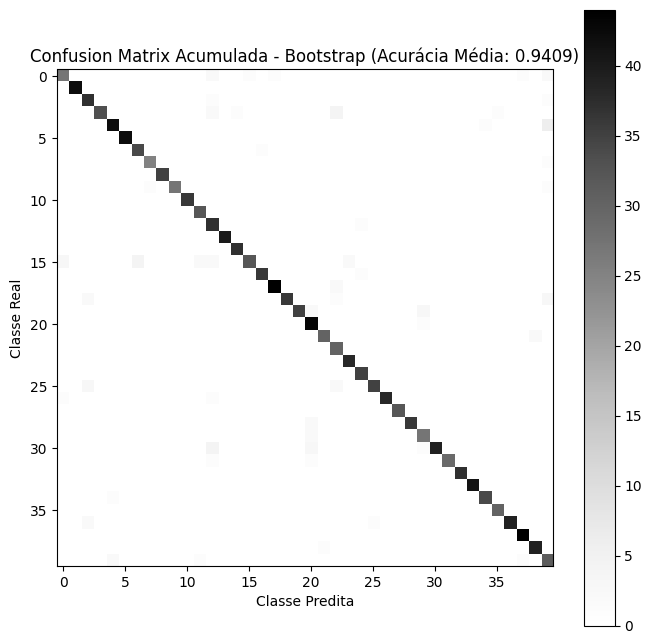

In [21]:
#Observando os resultados com matriz de confusão

plt.figure(figsize=(8, 8))
plt.imshow(cm_boot, cmap="Greys")
plt.title(
    f"Confusion Matrix Acumulada - Bootstrap (Acurácia Média: {acc_media_boot:.4f})"
)
plt.xlabel("Classe Predita")
plt.ylabel("Classe Real")
plt.colorbar()
plt.show()

# **COMENTÁRIOS SOBRE OS MÉTODOS E RESULTADOS**

O classificador escolhido foi o LDA (Linear Discriminant Analysis), que apresentou um ótimo desempenho na base Olivetti Faces, ficando acima de 94% de acurácia nos três métodos testados. Isso ocorre porque o LDA funciona muito bem em bases com muitos atributos (4096 pixels por imagem), conseguindo reduzir a dimensionalidade e separar bem as 40 classes.

Comparando o método direto (train_test_split) com o k-Fold, os resultados de acurácia foram bem próximos: 98,00% no train_test_split e 97,75% de média no k-Fold (com desvio padrão baixo, de 0,0166). Apesar do train_test_split ter dado um valor ligeiramente maior (errando apenas 2 imagens das 100 de teste), é possível notar pela matriz de confusão que a divisão aleatória deixou algumas classes com até 5 amostras de teste e outras sem nenhuma (pontos brancos na diagonal principal). Já no k-Fold com 5 divisões, todas as 400 imagens passaram pelo teste exatamente uma vez, gerando uma matriz de confusão acumulada com a diagonal principal bem uniforme (cerca de 10 acertos por classe e apenas 9 erros no total), o que torna o resultado do k-Fold mais confiável para avaliar o modelo.

No caso extra com Bootstrap (10 iterações), a acurácia média caiu para 94,09% (desvio padrão de 0,0226) e a matriz de confusão apresentou mais pontos de erro fora da diagonal principal. Essa queda acontece porque o sorteio do Bootstrap é feito com reposição. Com isso, várias imagens acabam repetidas no grupo de treino (que fica com cerca de 63% de imagens realmente diferentes), enquanto no k-Fold o treino conta sempre com 80% de imagens únicas (320 fotos). Como cada pessoa tem apenas 10 fotos na base, ter menos imagens inéditas no treino dificulta o aprendizado de todas as variações de rosto pelo classificador, reduzindo um pouco a acurácia final nos testes out-of-bag.

## Referências

[Scikit-Learn - Datasets - Olivetti Faces](http://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_olivetti_faces.html)

[Matplotlib - Pyplot](https://matplotlib.org/api/pyplot_summary.html)

[Numpy](https://docs.scipy.org/doc/numpy/reference/)

[Scikit-Learn - Train, Test and Split](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

[Scikit-Learn - KFold](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html#sklearn.model_selection.KFold)

[Scikit-Learn - Resample (Bootstrap)](http://scikit-learn.org/stable/modules/generated/sklearn.utils.resample.html)

[Scikit-Learn - KNeighborsClassifier](http://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)

[Scikit-Learn - DecisionTreeClassifier](http://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)

[Scikit-Learn - LinearDiscriminantAnalysis](http://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html)

[Scikit-Learn - LinearSVC](http://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html#sklearn.svm.LinearSVC)

[Scikit-Learn - MLPClassifier](http://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html#sklearn.neural_network.MLPClassifier)

[Scikit-Learn - Accuracy Score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html)

[Scikit-Learn - Confusion Matrix](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)